# **Crawling Paper Akademik**

# Crawling Paper Akademik (Scopus, ScienceDirect, WoS) & Download PDF

**Matakuliah:** Pencarian dan Penambangan Web (PPW)  
**Topik:** Systematic Literature Review (SLR) — Dampak Tutupan Awan pada Klasifikasi LULC Pertanian & Perkebunan Menggunakan Citra Sentinel-2 dan Deep Learning (2016–2026)

---
### 📌 Deskripsi Tugas
1. Melakukan crawling metadata artikel ilmiah dari **Scopus**, **ScienceDirect**, dan **Web of Science (WoS)** menggunakan API resmi.
2. Menggunakan kata kunci baru dari file `Kata Kunci baru.txt`.
3. Menggabungkan data, melakukan deduplikasi, dan melengkapi abstrak (OpenAlex / Semantic Scholar).
4. Melakukan download seluruh file PDF artikel open-access.
5. Mencatat daftar referensi yang tidak dapat didownload (closed-access / berbayar) untuk pembagian tugas mahasiswa.

## 1. Persiapan Environment & Import Modul
Memastikan pustaka yang dibutuhkan (`requests`, `pandas`, `matplotlib`) telah terpasang.

In [1]:
import os
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Pastikan direktori kerja berada di folder repo ppw
print("Current Working Directory:", os.getcwd())
print("Pandas Version:", pd.__version__)

Current Working Directory: d:\PPW\ppw
Pandas Version: 2.2.2


## 2. Konfigurasi API Key & Database
Masukkan API Key Elsevier yang sudah didapatkan. Key Elsevier dapat digunakan untuk **Scopus** dan **ScienceDirect** sekaligus.
> **Catatan:** Sesuai arahan, jika API Key Web of Science (WoS) belum disetujui, variabel `WOS_API_KEY` dapat dikosongkan dan database WoS akan dilewati secara otomatis.

In [2]:
# Masukkan API Key Anda di sini
SCOPUS_API_KEY = "5c93b7ad747a1f180a1e4661220a878d"
WOS_API_KEY = ""     # Kosongkan jika belum memiliki API Key WoS
EMAIL_USER = "anggerramdhan@gmail.com"     

# Set environment variables untuk modul crawling
if SCOPUS_API_KEY:
    os.environ["SCOPUS_API_KEY"] = SCOPUS_API_KEY
if WOS_API_KEY:
    os.environ["WOS_API_KEY"] = WOS_API_KEY

print("Status Konfigurasi:")
print("- Elsevier Key :", "Tersedia" if SCOPUS_API_KEY else "Belum diisi")
print("- WoS Key      :", "Tersedia" if WOS_API_KEY else "Dilewati / Kosong")
print("- Email        :", EMAIL_USER if EMAIL_USER else "Belum diisi")

Status Konfigurasi:
- Elsevier Key : Tersedia
- WoS Key      : Dilewati / Kosong
- Email        : anggerramdhan@gmail.com


## 3. Kata Kunci Baru & Penyesuaian Kueri Pencarian
Kata kunci baru yang digunakan berasal dari `Kata Kunci baru.txt`:
- **Sensor / Platform**: `Sentinel-2`, `multispectral imagery`, `optical satellite data`, `agricultural fields`
- **Metode**: `cloud removal`, `cloud reconstruction`, `gap-filling`, `deep learning`, `CNN`, `GAN`, `Transformer`
- **Komparasi / Kondisi**: `traditional methods`, `cloud masking`, `without cloud removal`, `statistical methods`
- **Metrik Evaluasi**: `classification accuracy`, `Overall Accuracy`, `OA`, `F1-Score`, `Kappa coefficient`, `performance improvement`
- **Aplikasi / Domain**: `agricultural land cover classification`, `crop type mapping`, `precision agriculture`, `remote sensing`

File `kueri_baru.py` telah disusun untuk memformat kata kunci tersebut sesuai sintaks masing-masing database (Scopus query, WoS query, dan ScienceDirect payload).

In [3]:
import kueri_baru

print("Rentang Tahun:", kueri_baru.TAHUN_MULAI, "-", kueri_baru.TAHUN_AKHIR)
print("\n--- Kueri Scopus ---\n", kueri_baru.SCOPUS[:300], "...")
print("\n--- Kueri ScienceDirect ---\n", json.dumps(kueri_baru.SCIENCEDIRECT, indent=2))

Rentang Tahun: 2016 - 2026

--- Kueri Scopus ---
 TITLE-ABS-KEY(("Sentinel-2" OR "multispectral imagery" OR "optical satellite data" OR "agricultural fields") AND ("cloud removal" OR "cloud reconstruction" OR "gap-filling" OR "deep learning" OR "CNN" OR "GAN" OR "Transformer") AND ("traditional methods" OR "cloud masking" OR "without cloud removal" ...

--- Kueri ScienceDirect ---
 [
  {
    "title": "\"Sentinel-2\" OR \"multispectral\" OR \"optical satellite\" OR \"agricultural\" OR \"crop\" OR \"land cover\" OR \"remote sensing\"",
    "qs": "(\"cloud removal\" OR \"cloud reconstruction\" OR \"gap-filling\") AND (\"deep learning\" OR \"CNN\" OR \"GAN\" OR \"Transformer\")"
  },
  {
    "title": "\"Sentinel-2\" OR \"land cover classification\" OR \"crop type mapping\" OR \"precision agriculture\" OR \"remote sensing\"",
    "qs": "(\"classification accuracy\" OR \"Overall Accuracy\" OR \"F1-Score\") AND (\"cloud masking\" OR \"traditional methods\" OR \"statistical methods\")"
  }
]


## 4. Eksekusi Crawling Metadata
Menjalankan fungsi crawling dari modul `slr_fetch.py`. Modul ini akan:
1. Mengambil metadata artikel dari Scopus & ScienceDirect (dan WoS jika ada key).
2. Menghapus duplikasi artikel berdasarkan DOI dan normalisasi judul.
3. Melengkapi abstrak secara otomatis menggunakan API OpenAlex dan Semantic Scholar.
4. Menyimpan data ke folder `hasil_slr/`.

In [4]:
# Memilih database yang aktif
active_sources = ["scopus", "sciencedirect"]
if WOS_API_KEY:
    active_sources.append("wos")

cmd_crawling = f"python slr_fetch.py --sources {' '.join(active_sources)} --config kueri_baru.py --out hasil_slr"
if EMAIL_USER:
    cmd_crawling += f" --email {EMAIL_USER}"

print("Perintah yang dijalankan:", cmd_crawling)
# Eksekusi via shell
!{cmd_crawling}

Perintah yang dijalankan: python slr_fetch.py --sources scopus sciencedirect --config kueri_baru.py --out hasil_slr --email anggerramdhan@gmail.com
[11:08:29] Kueri dibaca dari kueri_baru.py
[11:08:30] Scopus 2016: 0 hasil
[11:08:31] Scopus 2017: 0 hasil
[11:08:31] Scopus 2018: 0 hasil
[11:08:32] Scopus 2019: 1 hasil
[11:08:33] Scopus 2020: 1 hasil
[11:08:34] Scopus 2021: 0 hasil
[11:08:35] Scopus 2022: 1 hasil
[11:08:36] Scopus 2023: 4 hasil
[11:08:37] Scopus 2024: 5 hasil
[11:08:38] Scopus 2025: 7 hasil
[11:08:38] Scopus 2026: 15 hasil
[11:08:39] ScienceDirect GAGAL: ScienceDirect 2016: akses ditolak (HTTP 401). Periksa API key / hak akses.
Respons: {"service-error":{"status":{"statusCode":"AUTHORIZATION_ERROR","statusText":"The requestor is not authorized to access the requested view or fields of the resource"}}}
[11:08:39] Gabungan: 34 rekaman -> 34 unik (0 duplikat dihapus)
[11:08:39] OpenAlex: mencari abstrak untuk 32 rekaman...
[11:08:41] OpenAlex: 24 abstrak ditemukan
[11:08:41

## 5. Analisis & Eksplorasi Data Hasil Crawling
Membaca file `hasil_gabungan.csv` dan `log_pencarian.csv` untuk melihat ringkasan hasil.

In [5]:
csv_path = Path("hasil_slr/hasil_gabungan.csv")

if csv_path.exists():
    df = pd.read_csv(csv_path)
    print(f"Total artikel unik yang berhasil dikumpulkan: {len(df)}")
    display(df.head(5)[["title", "authors", "year", "journal", "source", "doi"]])
else:
    print("File hasil_gabungan.csv belum ada. Jalankan cell eksekusi crawling terlebih dahulu.")

Total artikel unik yang berhasil dikumpulkan: 34


,title,authors,year,journal,source,doi
0,Patch similarity convolutional neural network ...,Peng B.,2019,Remote Sensing,Scopus,10.3390/rs11212492
1,A CNN-Transformer Hybrid Approach for Crop Cla...,Li Z.,2020,IEEE Journal of Selected Topics in Applied Ear...,Scopus,10.1109/jstars.2020.2971763
2,Using time series vector features for annual c...,Lu X.,2022,Plos One,Scopus,10.1371/journal.pone.0272300
3,Comparisons between temporal statistical metri...,Liu X.,2023,Computers and Electronics in Agriculture,Scopus,10.1016/j.compag.2023.108015
4,Semantic segmentation model for land cover cla...,Lilay M.Y.,2023,SN Applied Sciences,Scopus,10.1007/s42452-023-05280-4


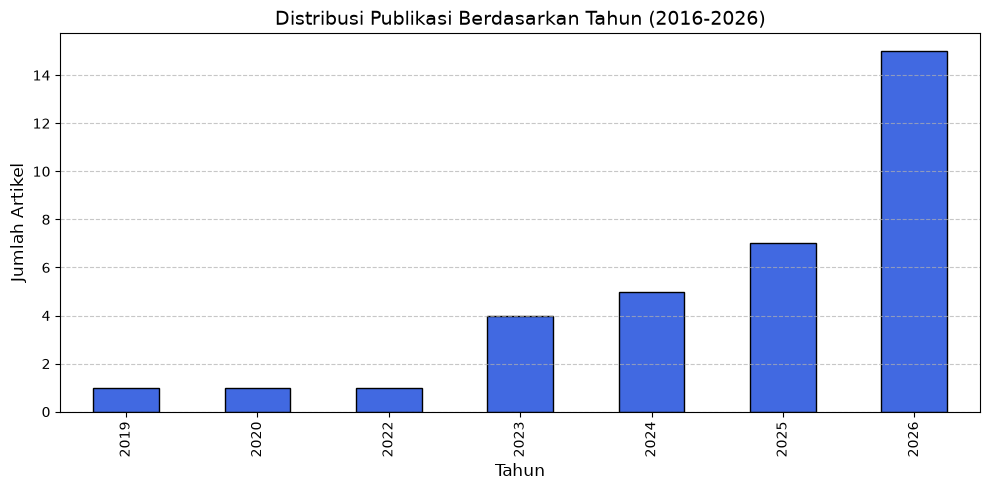

In [6]:
# Visualisasi tren publikasi per tahun
if csv_path.exists():
    df_year = df["year"].dropna().astype(str).value_counts().sort_index()
    plt.figure(figsize=(10, 5))
    df_year.plot(kind="bar", color="royalblue", edgecolor="black")
    plt.title("Distribusi Publikasi Berdasarkan Tahun (2016-2026)", fontsize=14)
    plt.xlabel("Tahun", fontsize=12)
    plt.ylabel("Jumlah Artikel", fontsize=12)
    plt.grid(axis="y", linestyle="--", alpha=0.7)
    plt.tight_layout()
    plt.show()

## 6. Download Seluruh File PDF & Pembagian Tugas Mahasiswa
Proses download dilakukan menggunakan API **Unpaywall** dan **Semantic Scholar** untuk mengambil artikel open-access secara legal dan gratis.

> **Catatan:** Sesuai instruksi dosen, proses download PDF dapat dibagi per mahasiswa berdasarkan rentang nomor indeks artikel (menggunakan opsi `--start` dan `--end`).

In [7]:
# Tentukan rentang artikel untuk mahasiswa yang bertugas
START_INDEX = 1   # Nomor awal artikel
END_INDEX = 50    # Nomor akhir artikel (0 = download seluruhnya)

cmd_download = f"python download_pdf.py --input hasil_slr/hasil_gabungan.csv --start {START_INDEX} --end {END_INDEX}"
if EMAIL_USER:
    cmd_download += f" --email {EMAIL_USER}"

print("Perintah Download:", cmd_download)
!{cmd_download}

Perintah Download: python download_pdf.py --input hasil_slr/hasil_gabungan.csv --start 1 --end 50 --email anggerramdhan@gmail.com
Total rekaman: 34
Memproses rekaman #1 s/d #34 (34 artikel)
  [1/34] Mencari PDF: Patch similarity convolutional neural network for urban floo...
    ✗ GAGAL download (file bukan PDF): 10.3390/rs11212492
  [2/34] Mencari PDF: A CNN-Transformer Hybrid Approach for Crop Classification Us...
    ✗ GAGAL download (file bukan PDF): 10.1109/jstars.2020.2971763
  [3/34] Mencari PDF: Using time series vector features for annual cultivated land...
    ✓ BERHASIL (Unpaywall, 3352 KB): 0003_2022_Using_time_series_vector_features_for_annual_cultivated_land.pdf
  [4/34] Mencari PDF: Comparisons between temporal statistical metrics, time serie...
    ✗ GAGAL download (file bukan PDF): 10.1016/j.compag.2023.108015
  [5/34] Mencari PDF: Semantic segmentation model for land cover classification fr...
    ✗ GAGAL download (file bukan PDF): 10.1007/s42452-023-05280-4
  [6/34] 

## 7. Rekapitulasi Artikel yang Tidak Dapat Didownload
Artikel yang berbayar (closed access) atau tidak memiliki tautan PDF gratis akan dicatat ke dalam `gagal_download.csv` beserta tautan DOI-nya agar dapat diunduh manual melalui repositori kampus atau perpustakaan.

In [8]:
gagal_path = Path("pdf_downloads/gagal_download.csv")
berhasil_path = Path("pdf_downloads/berhasil_download.csv")

if berhasil_path.exists():
    df_berhasil = pd.read_csv(berhasil_path)
    print(f"✓ Total PDF Berhasil Diunduh: {len(df_berhasil)}")

if gagal_path.exists():
    df_gagal = pd.read_csv(gagal_path)
    print(f"✗ Total PDF Gagal Diunduh (Closed Access): {len(df_gagal)}")
    print("\nDaftar Referensi yang Tidak Dapat Didownload Otomatis:")
    display(df_gagal[["no", "title", "year", "source", "alasan", "link"]].head(10))
else:
    print("Daftar gagal_download.csv belum tersedia. Jalankan proses download terlebih dahulu.")

✓ Total PDF Berhasil Diunduh: 2
✗ Total PDF Gagal Diunduh (Closed Access): 32

Daftar Referensi yang Tidak Dapat Didownload Otomatis:


,no,title,year,source,alasan,link
0,1,Patch similarity convolutional neural network ...,2019,Scopus,File bukan PDF (Unpaywall),https://doi.org/10.3390/rs11212492
1,2,A CNN-Transformer Hybrid Approach for Crop Cla...,2020,Scopus,File bukan PDF (Unpaywall),https://doi.org/10.1109/jstars.2020.2971763
2,4,Comparisons between temporal statistical metri...,2023,Scopus,File bukan PDF (Unpaywall),https://doi.org/10.1016/j.compag.2023.108015
3,5,Semantic segmentation model for land cover cla...,2023,Scopus,File bukan PDF (Unpaywall),https://doi.org/10.1007/s42452-023-05280-4
4,6,Extracting Tea Plantations from Multitemporal ...,2023,Scopus,File bukan PDF (Unpaywall),https://doi.org/10.3390/agriculture13010010
5,7,Land cover classification using Land Parcel Id...,2023,Scopus,File bukan PDF (Unpaywall),https://doi.org/10.1080/10106049.2022.2146760
6,8,Monitoring the Distribution of Mangrove Area u...,2024,Scopus,Tidak ada DOI,NaN
7,9,Intelligent Water Body Delineation for Flood M...,2024,Scopus,Tidak ada PDF open-access,https://doi.org/10.1109/aisp61711.2024.10870599
8,10,A Novel Coral Reef Classification Method Combi...,2024,Scopus,File bukan PDF (Unpaywall),https://doi.org/10.1109/jstars.2024.3430899
9,11,From Pixels to Patterns: A Review of Land Cove...,2024,Scopus,Tidak ada DOI,NaN
